# The question and the setup

A working paper presented at a conference in November 2026 argued that the Earth warmed fastest in 1899–1940,
when carbon dioxide (CO₂) emissions were small, and concluded that CO₂ is not the main driver of warming.
In this notebook we test that claim ourselves, from public data, one step at a time. By the end you will have
downloaded four datasets, joined them into one table, fitted trend lines by hand and with a library, measured
how uncertain those trends are, built a small physical model of the climate, and made the figures that answer
the question.

Each code cell is followed by its output, exactly as it appeared when this notebook was run. Run the cells in
order from the top: later cells use what earlier cells made.

We use four Python libraries. **pandas** holds tables (rows and columns, like a spreadsheet); **numpy** does
arithmetic on whole columns at once; **matplotlib** draws figures; and **scipy** provides statistical tests.

In [1]:
import json
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.0.1 | pandas 2.2.3


# Download the data

Every number in this notebook comes from four public files. Each is downloaded once into a folder called `data`
next to the notebook, and reused after that. Writing the download as code, rather than clicking in a browser,
means anyone can repeat it exactly.

| File | What it holds | Who publishes it |
|---|---|---|
| `hadcrut5.csv` | Global temperature anomaly, one row per year since 1850 | Met Office Hadley Centre and University of East Anglia |
| `conus.csv` | Temperature of the contiguous United States, one row per year since 1895 | NOAA |
| `owid_co2.csv` | CO₂ emitted by every country, every year | Our World in Data |
| `forcing.csv` | Radiative forcing by cause, one row per year since 1750 | Indicators of Global Climate Change |

In [2]:
DATA = Path("data")
DATA.mkdir(exist_ok=True)
SOURCES = {
    "hadcrut5.csv": "https://www.metoffice.gov.uk/hadobs/hadcrut5/data/HadCRUT.5.0.2.0/analysis/diagnostics/"
                    "HadCRUT.5.0.2.0.analysis.summary_series.global.annual.csv",
    "conus.csv": "https://www.ncei.noaa.gov/access/monitoring/climate-at-a-glance/national/time-series/110/tavg/12/12/1895-2024/data.csv",
    "owid_co2.csv": "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv",
    "forcing.csv": "https://raw.githubusercontent.com/ClimateIndicator/forcing-timeseries/main/output/ERF_best_aggregates_1750-2024.csv",
}
for name, url in SOURCES.items():
    target = DATA / name
    if not target.exists():
        req = urllib.request.Request(url, headers={"User-Agent": "climate-data-notebook/1.0"})
        target.write_bytes(urllib.request.urlopen(req, timeout=120).read())
    print(f"{name:14s} {target.stat().st_size / 1e6:6.2f} MB")

hadcrut5.csv     0.01 MB


conus.csv        0.00 MB


owid_co2.csv    14.38 MB


forcing.csv      0.10 MB


# Look inside each file

Before using any data, look at it: how many rows and columns, what the columns are called, and what a few rows
contain. `pd.read_csv` reads a file into a table called a DataFrame; `.shape` gives (rows, columns); `.head()`
shows the first rows.

**HadCRUT5.** The anomaly is the temperature minus the average of 1961–1990, so 0 means "normal", positive
means warmer than normal. The two limits give the range within which the true value lies with 95% probability.

In [3]:
g = pd.read_csv(DATA / "hadcrut5.csv")
print(g.shape)
print(g.head(3).to_string())
print("...")
print(g.tail(2).to_string())

(176, 4)
   Time  Anomaly (deg C)  Lower confidence limit (2.5%)  Upper confidence limit (97.5%)
0  1850        -0.417711                      -0.589256                       -0.246166
1  1851        -0.233350                      -0.411868                       -0.054832
2  1852        -0.229399                      -0.409382                       -0.049416
...
     Time  Anomaly (deg C)  Lower confidence limit (2.5%)  Upper confidence limit (97.5%)
174  2024         1.180800                       1.141589                        1.220011
175  2025         1.190283                       1.048175                        1.332391


The last row is the current year, which is not finished, so we will stop at 2024.

**NOAA contiguous US.** The file starts with lines beginning `#`, which are notes; `comment="#"` skips them. The
`Date` 189512 means the twelve months ending December 1895. Values are in degrees Fahrenheit.

In [4]:
us_raw = pd.read_csv(DATA / "conus.csv", comment="#")
print(us_raw.shape)
print(us_raw.head(3).to_string())

(130, 2)
     Date  Value
0  189512  50.33
1  189612  51.98
2  189712  51.54


**Our World in Data.** One row per country per year, with 79 columns. We keep only the rows for the whole
World and two columns: `co2`, the CO₂ emitted that year, and `cumulative_co2`, the running total since records
began. Both are in millions of tonnes; dividing by 1,000 gives gigatonnes (Gt).

In [5]:
owid = pd.read_csv(DATA / "owid_co2.csv", usecols=["country", "year", "co2", "cumulative_co2"])
print(owid.shape, "rows and columns;", owid.country.nunique(), "countries and regions")
world = owid[owid.country == "World"].drop(columns="country")
print(world[world.year.isin([1900, 1950, 2000, 2024])].to_string(index=False))

(50411, 4) rows and columns; 254 countries and regions
 year       co2  cumulative_co2
 1900  1962.884       45105.176
 1950  5930.406      231890.109
 2000 25511.482     1045316.812
 2024 38598.578     1849123.875


**Radiative forcing.** Radiative forcing is the extra energy, in watts per square metre of the Earth's surface
(W/m²), flowing into the climate because something changed: more greenhouse gases (positive, warming), more
sulfate pollution (negative, cooling), a brighter Sun, a volcanic eruption. Each column is one cause; `anthro`
is all human causes together and `total` adds the natural ones.

In [6]:
f = pd.read_csv(DATA / "forcing.csv").rename(columns={"Unnamed: 0": "year"})
f["year"] = f["year"].astype(int)
print(f.shape)
print(f[["year", "CO2", "aerosol", "solar", "volcanic", "anthro", "total"]].iloc[[100, 200, 274]].round(3).to_string(index=False))

(275, 19)
 year   CO2  aerosol  solar  volcanic  anthro  total
 1850 0.140   -0.083  0.008     0.244   0.114  0.365
 1950 0.648   -0.714  0.057     0.218   0.344  0.618
 2024 2.332   -1.066  0.091     0.238   2.974  3.303


# Prepare: units, baselines and one joined table

Three preparation steps. **Units:** convert NOAA's Fahrenheit to Celsius with °C = (°F − 32) × 5/9.
**Baseline:** turn the US temperatures into anomalies by subtracting their 1901–2000 mean. **Join:** put
everything into one table with one row per year, matching rows on the `year` column with `merge`.

A worked example of the conversion for 2024: NOAA gives 55.48 °F, so (55.48 − 32) × 5/9 = 13.04 °C.

In [7]:
us = pd.DataFrame({"year": us_raw["Date"] // 100, "conus": (us_raw["Value"] - 32) * 5 / 9})
base = us.loc[us.year.between(1901, 2000), "conus"].mean()
print(f"US 1901-2000 mean: {base:.2f} °C; 2024: {us.conus.iloc[-1]:.2f} °C, anomaly {us.conus.iloc[-1] - base:+.2f} °C")
us["conus"] -= base

d = (g.rename(columns={"Time": "year", "Anomaly (deg C)": "global"})[["year", "global"]]
       .merge(us, on="year", how="left")
       .merge(world, on="year", how="left")
       .merge(f[["year", "anthro", "aerosol", "solar", "volcanic", "total"]], on="year", how="left"))
d = d[d.year <= 2024].reset_index(drop=True)
print(d.shape)
print(d[d.year.isin([1900, 1940, 1982, 2024])].round(3).to_string(index=False))

US 1901-2000 mean: 11.12 °C; 2024: 13.04 °C, anomaly +1.93 °C
(175, 10)
 year  global  conus       co2  cumulative_co2  anthro  aerosol  solar  volcanic  total
 1900  -0.234  0.417  1962.884       45105.176   0.124   -0.366 -0.037     0.179  0.265
 1940   0.076 -0.072  4884.662      181025.359   0.304   -0.658  0.040     0.227  0.571
 1982   0.034 -0.378 18729.742      640191.688   0.809   -1.393  0.067    -0.244  0.632
 2024   1.181  1.928 38598.578     1849123.875   2.974   -1.066  0.091     0.238  3.303


`how="left"` keeps every year of the first table; where another table has no value for that year (the US series
starts in 1895) the cell is `NaN`, which means "no value". Missing values are skipped by the calculations below.

# A trend line, by hand and for every window

A trend is the slope of the straight line that best fits the points. "Best" means the line that makes the sum of
the squared vertical distances from the points to the line as small as possible: ordinary least squares (OLS).
For points (x, y), with x̄ and ȳ their means, the slope is

$$ b = \frac{\sum (x - \bar x)(y - \bar y)}{\sum (x - \bar x)^2} $$

It is in degrees per year; multiplying by ten gives degrees per decade. Here it is by hand, for five years:

In [8]:
small = d[d.year.between(2010, 2014)][["year", "global"]].copy()
small["x - xbar"] = small.year - small.year.mean()
small["y - ybar"] = small["global"] - small["global"].mean()
small["product"] = small["x - xbar"] * small["y - ybar"]
small["(x - xbar)^2"] = small["x - xbar"] ** 2
print(small.round(4).to_string(index=False))
b = small["product"].sum() / small["(x - xbar)^2"].sum()
print(f"\nslope = {small['product'].sum():.4f} / {small['(x - xbar)^2'].sum():.0f} = {b:.4f} °C per year")
print(f"numpy gives {np.polyfit(small.year, small['global'], 1)[0]:.4f}")

 year  global  x - xbar  y - ybar  product  (x - xbar)^2
 2010  0.6804      -2.0    0.0619  -0.1239           4.0
 2011  0.5377      -1.0   -0.0807   0.0807           1.0
 2012  0.5776       0.0   -0.0408  -0.0000           0.0
 2013  0.6236       1.0    0.0052   0.0052           1.0
 2014  0.6729       2.0    0.0544   0.1089           4.0

slope = 0.0709 / 10 = 0.0071 °C per year


numpy gives 0.0071


Five years is far too short for climate: a single El Niño year can tip the slope either way. The paper used
42-year windows, so we do the same, for the global record and for the United States.

In [9]:
WINDOWS = [(1899, 1940), (1941, 1982), (1983, 2024)]
rows = []
for a, e in WINDOWS:
    w = d[d.year.between(a, e)]
    for col in ["global", "conus"]:
        slope = np.polyfit(w.year, w[col], 1)[0] * 10
        rows.append({"window": f"{a}-{e}", "series": col, "trend per decade": round(slope, 3),
                     "CO2 emitted (Gt)": round(w.co2.sum() / 1000), "change in human forcing (W/m2)": round(w.anthro.iloc[-1] - w.anthro.iloc[0], 2)})
trends = pd.DataFrame(rows)
print(trends.to_string(index=False))

   window series  trend per decade  CO2 emitted (Gt)  change in human forcing (W/m2)
1899-1940 global             0.101               140                            0.18
1899-1940  conus             0.168               140                            0.18
1941-1982 global             0.012               459                            0.51
1941-1982  conus            -0.059               459                            0.51
1983-2024 global             0.216              1209                            2.05
1983-2024  conus             0.280              1209                            2.05


Both the globe and the United States warmed fastest in the most recent window, 1983–2024, not in 1899–1940.

# Neighbouring years are not independent

How sure are we of each slope? The standard error (SE) of a slope measures how much it would vary if the
"noise" around the line were drawn again. The usual formula assumes every point is an independent piece of
information. Climate years are not: a warm year tends to follow a warm year, because the oceans store heat and
El Niño lasts more than one year. This is **autocorrelation**. We measure it with the lag-1 correlation r₁ of
the leftovers (residuals) after removing the trend, and then count how many independent years we really have:

$$ n_{\text{eff}} = n \, \frac{1 - r_1}{1 + r_1} $$

The SE grows accordingly. `scipy.stats.linregress` gives the slope and the naive SE; we then correct it.

In [10]:
def trend_with_uncertainty(years, values):
    fit = stats.linregress(years, values)
    resid = values - (fit.intercept + fit.slope * years)
    r1 = np.corrcoef(resid[:-1], resid[1:])[0, 1]
    n = len(values)
    n_eff = n * (1 - r1) / (1 + r1) if r1 > 0 else n
    se = fit.stderr * np.sqrt((n - 2) / max(n_eff - 2, 1))
    return {"trend": fit.slope * 10, "se_naive": fit.stderr * 10, "r1": r1, "n_eff": n_eff, "se_corrected": se * 10}

rows = []
for a, e in WINDOWS:
    w = d[d.year.between(a, e)]
    t = trend_with_uncertainty(w.year.to_numpy(float), w["global"].to_numpy())
    rows.append({"window": f"{a}-{e}", **{k: round(v, 3) for k, v in t.items()}})
unc = pd.DataFrame(rows)
print(unc.to_string(index=False))

   window  trend  se_naive    r1  n_eff  se_corrected
1899-1940  0.101     0.014 0.483 14.648         0.026
1941-1982  0.012     0.016 0.475 14.935         0.028
1983-2024  0.216     0.013 0.217 27.023         0.016


Read the table: in 1983–2024 the global trend is about 0.22 °C per decade with a corrected SE of about 0.02. A
95% range is roughly the trend ± 2 SE, so 0.18 to 0.25. In 1899–1940 it is about 0.10 ± 0.05. The ranges do not
overlap: the recent warming really is faster.

# Forcing and a simple energy-balance model

Temperature responds to the total forcing, not to the CO₂ emitted in a window. To see this we build the simplest
useful climate model: two reservoirs of heat. The first (land, air, upper ocean) responds within a few years; the
second (deep ocean) over centuries. Each year, each reservoir keeps most of last year's warmth and moves a little
towards the level the current forcing would eventually produce:

$$ T_j(t) = T_j(t-1)\, e^{-1/\tau_j} + q_j\, F(t)\,(1 - e^{-1/\tau_j}) $$

with τ the response time (4 and 250 years) and q the sensitivity (0.33 and 0.41 °C per W/m²), values typical of
the calibrations in the IPCC's Sixth Assessment Report. The temperature is the sum of the two reservoirs.

In [11]:
def respond(forcing, tau=(4.0, 250.0), q=(0.33, 0.41)):
    out = np.zeros(len(forcing))
    for t_, q_ in zip(tau, q):
        a, box = np.exp(-1 / t_), 0.0
        for i, F in enumerate(forcing):
            box = box * a + q_ * F * (1 - a)
            out[i] += box
    return out

# a step of 1 W/m2 switched on in year 2, to see how the model behaves
step = respond(np.r_[0, 0, np.ones(8)])
print("years 0-9 after a 1 W/m2 step:", np.round(step, 3))

years 0-9 after a 1 W/m2 step: [0.    0.    0.075 0.133 0.179 0.215 0.244 0.266 0.284 0.298]


The fast reservoir warms by about 0.07 °C in the first year and keeps rising; the slow one barely moves in ten
years. Now we feed in each real cause of forcing separately, at its published size, and add them up.

In [12]:
f24 = f[f.year <= 2024].reset_index(drop=True)
parts = pd.DataFrame({"year": f24.year,
                      "greenhouse and other": respond((f24.anthro - f24.aerosol).to_numpy()),
                      "aerosol": respond(f24.aerosol.to_numpy()),
                      "solar": respond(f24.solar.to_numpy()),
                      "volcanic": respond(f24.volcanic.to_numpy())})
m = d[["year", "global"]].merge(parts, on="year")
causes = ["greenhouse and other", "aerosol", "solar", "volcanic"]
offset = (m["global"] - m[causes].sum(axis=1)).mean()        # the only thing fitted: the baseline
m["model"] = m[causes].sum(axis=1) + offset
m["unexplained"] = m["global"] - m["model"]
r2 = 1 - (m.unexplained ** 2).sum() / ((m["global"] - m["global"].mean()) ** 2).sum()
print(f"share of year-to-year variation the model explains: {r2:.0%}")

share of year-to-year variation the model explains: 87%


# What drove each period

Because the model is a sum of causes, each period's trend splits into the trend of each part. The parts add up to
the observed trend exactly, with the "unexplained" column holding what forcing does not account for: natural
swings in the oceans and measurement errors.

In [13]:
rows = []
for a, e in [(1910, 1945), (1946, 1975), (1976, 2024)]:
    w = m[m.year.between(a, e)]
    rows.append({"period": f"{a}-{e}", **{c: round(np.polyfit(w.year, w[c], 1)[0] * 10, 3) for c in ["global", *causes, "unexplained"]}})
split = pd.DataFrame(rows)
print(split.to_string(index=False))

   period  global  greenhouse and other  aerosol  solar  volcanic  unexplained
1910-1945   0.156                 0.048   -0.021  0.004     0.009        0.116
1946-1975  -0.004                 0.094   -0.088  0.001    -0.010       -0.001
1976-2024   0.204                 0.183   -0.001 -0.003     0.018        0.007


Since the mid-1970s greenhouse gases account for almost all of the warming. In 1946–1975 their warming was
cancelled by aerosol cooling. In 1910–1945 forcing explains only part of the warming; the rest is natural
variability, which climate scientists already knew.

# Making and reading the figures

A figure answers a question only if you can say what each part shows. Before reading any chart, name its parts:
what one mark is (a year, a bar), which column of the table goes on the x axis and which on the y axis, and in
what units; what colour encodes; and whether uncertainty is shown.

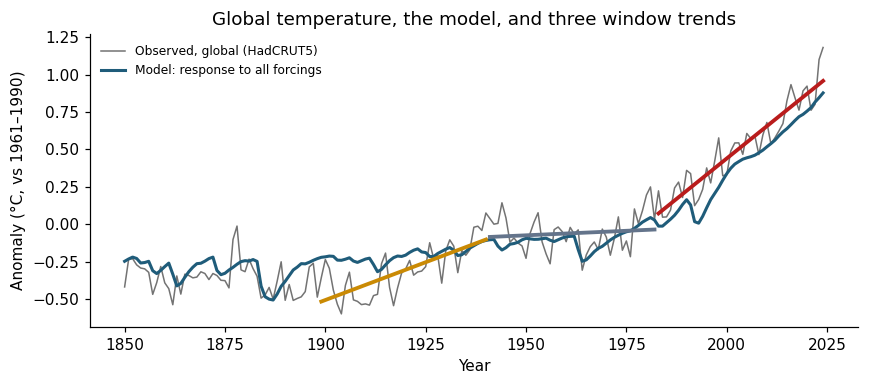

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(d.year, d["global"], color="0.45", lw=1, label="Observed, global (HadCRUT5)")      # x: column 'year', y: column 'global'
ax.plot(m.year, m.model, color="#1f5c7a", lw=2, label="Model: response to all forcings")    # y: column 'model'
for (a, e), col in zip(WINDOWS, ["#ca8a04", "#64748b", "#b91c1c"]):                          # one trend line per window
    w = d[d.year.between(a, e)]
    k = np.polyfit(w.year, w["global"], 1)
    ax.plot(w.year, np.polyval(k, w.year), color=col, lw=2.5)
ax.set(xlabel="Year", ylabel="Anomaly (°C, vs 1961–1990)", title="Global temperature, the model, and three window trends")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Reading it: the x axis is the `year` column; the y axis is the anomaly in °C. Each point on the grey line is one
row of the table. The coloured segments are the three window trends from the trend table: the red one, 1983–2024,
is the steepest. The blue line is the model, which knows nothing of the observed temperatures except their
average level, yet follows the long rise, the dips after volcanic eruptions and the mid-century flat period.

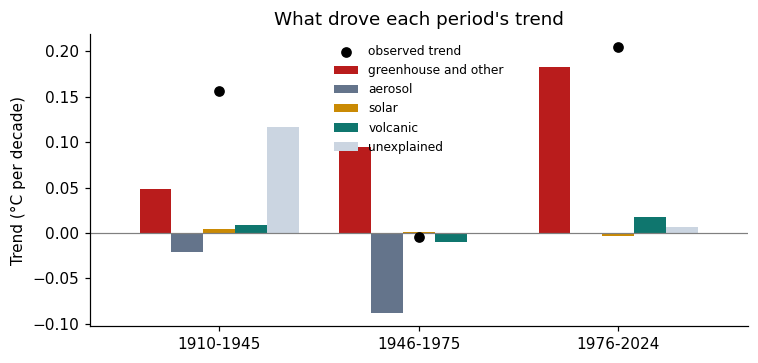

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.4))
split.set_index("period")[[*causes, "unexplained"]].plot.bar(ax=ax, width=0.8,
    color=["#b91c1c", "#64748b", "#ca8a04", "#0f766e", "#cbd5e1"])
ax.scatter(range(len(split)), split["global"], color="k", zorder=3, label="observed trend")
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xlabel="", ylabel="Trend (°C per decade)", title="What drove each period's trend")
ax.legend(frameon=False, fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Reading it: one group of bars per row of the `split` table; one bar per cause column; the height is that cause's
trend in °C per decade, below zero for cooling. The black dot is the observed trend; the bars in each group add up
to it.

# Recording what the run used

Good practice is to record what each run used: the versions of the libraries, the size of the data, and the time
it took. Then anyone can see what they need to repeat it, and you can compare when the work grows.

In [16]:
record = {"python_packages": {"numpy": np.__version__, "pandas": pd.__version__},
          "data_files_mb": {p.name: round(p.stat().st_size / 1e6, 2) for p in sorted(DATA.glob("*.csv"))},
          "rows_in_joined_table": len(d),
          "result": {"global_trend_1983_2024": round(float(unc.trend.iloc[2]), 3), "global_trend_1899_1940": round(float(unc.trend.iloc[0]), 3)}}
print(json.dumps(record, indent=1))

{
 "python_packages": {
  "numpy": "2.0.1",
  "pandas": "2.2.3"
 },
 "data_files_mb": {
  "conus.csv": 0.0,
  "forcing.csv": 0.1,
  "hadcrut5.csv": 0.01,
  "owid_co2.csv": 14.38
 },
 "rows_in_joined_table": 175,
 "result": {
  "global_trend_1983_2024": 0.216,
  "global_trend_1899_1940": 0.101
 }
}
